Explanatory Data Analysis

In [4]:

from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

DATA = Path("C:/Users/lydia/Research-SWE/LUNA-Analysis/data")                      
IMG_DIR = DATA / "CT" / "CT" / "image"
MASK_DIR = DATA / "CT" / "CT" / "nodule_mask"  

scan_files = sorted(IMG_DIR.glob("*.nii.gz"))
print(f"{len(scan_files)} scans found")

3 scans found


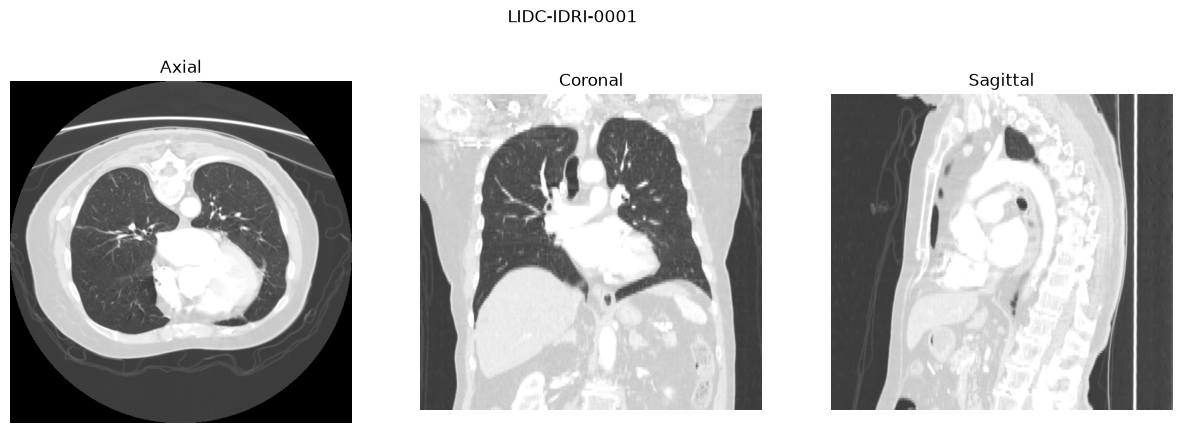

In [5]:
def load_scan(path):
    img = nib.load(path)
    vol = np.asanyarray(img.dataobj).astype(np.float32)   
    return img, vol

def show_three_views(path, window=(-1400, 200)):
    img, vol = load_scan(path)
    sx, sy, sz = img.header.get_zooms()[:3]
    x, y, z = (s // 2 for s in vol.shape)
    kw = dict(cmap="gray", vmin=window[0], vmax=window[1], origin="lower")

    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(vol[:, :, z].T, aspect=sy / sx, **kw); ax[0].set_title("Axial")
    ax[1].imshow(vol[:, y, :].T, aspect=sz / sx, **kw); ax[1].set_title("Coronal")
    ax[2].imshow(vol[x, :, :].T, aspect=sz / sy, **kw); ax[2].set_title("Sagittal")
    for a in ax: a.axis("off")
    fig.suptitle(path.name.replace(".nii.gz", ""))
    plt.show()

show_three_views(scan_files[0])

In [6]:
rows = []
for p in scan_files:
    img = nib.load(p)
    sx, sy, sz = img.header.get_zooms()[:3]
    rows.append({
        "patient_id": p.name.replace(".nii.gz", ""),
        "shape": img.shape,
        "n_slices": img.shape[2],
        "sx": sx, "sy": sy, "sz": sz,
        "orientation": "".join(nib.aff2axcodes(img.affine)),
    })
inv = pd.DataFrame(rows)
print(inv.describe())
print(inv["orientation"].value_counts())    # are all scans in the same orientation?
inv.to_csv("C:/Users/lydia/Research-SWE/LUNA-Analysis/data/processedscan_inventory.csv", index=False)

         n_slices        sx        sy   sz
count    3.000000  3.000000  3.000000  3.0
mean   135.333333  0.729166  0.729166  2.5
std      4.041452  0.081315  0.081315  0.0
min    133.000000  0.664062  0.664062  2.5
25%    133.000000  0.683594  0.683594  2.5
50%    133.000000  0.703125  0.703125  2.5
75%    136.500000  0.761719  0.761719  2.5
max    140.000000  0.820312  0.820312  2.5
orientation
LPS    3
Name: count, dtype: int64


In [7]:
# --- Cell 4: the Excel file (you only printed head() so far) ---
df = pd.read_excel(DATA / "MetadatabyAnnotation.xlsx")
print(df.shape)
print(df.columns.tolist())
df.info()
df.isna().sum()

(3674, 33)
['patient_id', 'nodule_id', 'seriesuid', 'coordX', 'coordY', 'coordZ', 'diameter_mm', 'bboxLowX', 'bboxLowY', 'bboxLowZ', 'bboxHighX', 'bboxHighY', 'bboxHighZ', 'Malignancy', 'Malignancy_value', 'anotation_id', 'Calcification', 'Calcification_value', 'InternalStructure', 'InternalStructure_value', 'Lobulation', 'Lobulation_value', 'Margin', 'Margin_value', 'Sphericity', 'Sphericity_value', 'Spiculation', 'Spiculation_value', 'Subtlety', 'Subtlety_value', 'Texture', 'Texture_value', 'len_mal_details']
<class 'pandas.DataFrame'>
RangeIndex: 3674 entries, 0 to 3673
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   patient_id               3674 non-null   str    
 1   nodule_id                3674 non-null   int64  
 2   seriesuid                3674 non-null   str    
 3   coordX                   3674 non-null   float64
 4   coordY                   3674 non-null   float64
 5   coor

patient_id                 0
nodule_id                  0
seriesuid                  0
coordX                     0
coordY                     0
coordZ                     0
diameter_mm                0
bboxLowX                   0
bboxLowY                   0
bboxLowZ                   0
bboxHighX                  0
bboxHighY                  0
bboxHighZ                  0
Malignancy                 0
Malignancy_value           0
anotation_id               0
Calcification              0
Calcification_value        0
InternalStructure          0
InternalStructure_value    0
Lobulation                 0
Lobulation_value           0
Margin                     0
Margin_value               0
Sphericity                 0
Sphericity_value           0
Spiculation                0
Spiculation_value          0
Subtlety                   0
Subtlety_value             0
Texture                    0
Texture_value              0
len_mal_details            0
dtype: int64

In [8]:
pid = df["patient_id"].iloc[0]
print(repr(pid), df["patient_id"].dtype)

cols = ["patient_id", "nodule_id", "anotation_id", "Malignancy",
        "Malignancy_value", "len_mal_details", "coordX", "diameter_mm"]
df[df["patient_id"] == pid][cols]      # all rows for the first patient

# are coordinates identical across annotations of the same nodule?
print(df.groupby(["patient_id", "nodule_id"])["coordX"].nunique().value_counts())
print(df.groupby(["patient_id", "nodule_id"]).size().value_counts())

'LIDC-IDRI-0001' str
coordX
1    995
2      1
Name: count, dtype: int64
4    667
3    323
5      3
6      1
9      1
7      1
Name: count, dtype: int64


In [9]:
import ast

def parse_ratings(v):
    """Return a list of ints whether v is a number or a string like '[5, 5, 5, 4]'."""
    if isinstance(v, str):
        return [int(r) for r in ast.literal_eval(v)]
    return [int(v)]

def is_malignant(ratings):
    return int(sum(r > 3 for r in ratings) >= 2)

# Test cases from the PDF (nodule 1 of LIDC-IDRI-0001 and LIDC-IDRI-0004)
assert is_malignant([5, 5, 5, 4]) == 1
assert is_malignant([2, 1, 1, 1]) == 0

In [10]:
nod = (df.groupby(["patient_id", "nodule_id"])
         .agg(ratings=("Malignancy_value", list),
              n_annotations=("anotation_id", "nunique"),
              diameter_mm=("diameter_mm", "mean"))
         .reset_index())
nod["malignant"] = nod["ratings"].apply(is_malignant)
print(nod["malignant"].value_counts())
print(nod["n_annotations"].value_counts())   # how many nodules have only 1 annotator?

malignant
0    650
1    346
Name: count, dtype: int64
n_annotations
4    667
3    323
5      3
6      1
9      1
7      1
Name: count, dtype: int64


In [11]:
import numpy as np

row = df[df["patient_id"] == "LIDC-IDRI-0001"].iloc[0]   # adjust to your ID format
img = nib.load(IMG_DIR / "LIDC-IDRI-0001.nii.gz")
inv_aff = np.linalg.inv(img.affine)

x, y, z = row["coordX"], row["coordY"], row["coordZ"]
for label, pt in [("as given", (x, y, z)), ("flip x,y", (-x, -y, z))]:
    ijk = (inv_aff @ np.array([*pt, 1]))[:3]
    print(label, np.round(ijk, 1), "inside volume:",
          all(0 <= v < s for v, s in zip(ijk, img.shape)))

as given [156.1 121.4  89.7] inside volume: True
flip x,y [316.  367.   89.7] inside volume: True


In [12]:
counts = df.groupby(["patient_id", "nodule_id"]).size()
odd = counts[counts > 4].index.tolist()

n_coord = df.groupby(["patient_id", "nodule_id"])["coordX"].nunique()
odd += n_coord[n_coord > 1].index.tolist()

cols = ["patient_id", "nodule_id", "anotation_id", "Malignancy_value",
        "coordX", "coordY", "coordZ", "diameter_mm"]
for pid, nid in sorted(set(odd)):
    print(df[(df.patient_id == pid) & (df.nodule_id == nid)][cols], "\n")

          patient_id  nodule_id  anotation_id  Malignancy_value     coordX  \
1061  LIDC-IDRI-0204          1          1717                 4  58.512663   
1062  LIDC-IDRI-0204          1          1718                 3  58.512663   
1063  LIDC-IDRI-0204          1          1719                 5  58.512663   
1064  LIDC-IDRI-0204          1          1720                 5  58.512663   
1065  LIDC-IDRI-0204          1          1721                 4  58.512663   
1066  LIDC-IDRI-0204          1          1722                 4  58.512663   

         coordY      coordZ  diameter_mm  
1061  75.794013 -279.292424     15.99235  
1062  75.794013 -279.292424     15.99235  
1063  75.794013 -279.292424     15.99235  
1064  75.794013 -279.292424     15.99235  
1065  75.794013 -279.292424     15.99235  
1066  75.794013 -279.292424     15.99235   

          patient_id  nodule_id  anotation_id  Malignancy_value     coordX  \
1259  LIDC-IDRI-0252          1          1981                 5 -52.4193

In [13]:
VOI_IMG = DATA / "VOIs" / "VOIs" / "image"
voi_files = sorted(VOI_IMG.glob("*.nii.gz"))
print(len(voi_files), [p.name for p in voi_files[:3]])
print(sorted((DATA / "VOIs" / "VOIs").iterdir()))        # is there a mask folder too?
print(len(scan_files), "full CT scans")

print(nod["nodule_id"].head())                            # int or string like "R_1"?
nod["voi_name"] = nod["patient_id"] + "_R_" + nod["nodule_id"].astype(str) + ".nii.gz"
nod["has_voi"] = nod["voi_name"].isin({p.name for p in voi_files})
print(nod["has_voi"].value_counts())

994 ['LIDC-IDRI-0001_R_1.nii.gz', 'LIDC-IDRI-0003_R_2.nii.gz', 'LIDC-IDRI-0003_R_3.nii.gz']
[WindowsPath('C:/Users/lydia/Research-SWE/LUNA-Analysis/data/VOIs/VOIs/.DS_Store'), WindowsPath('C:/Users/lydia/Research-SWE/LUNA-Analysis/data/VOIs/VOIs/image'), WindowsPath('C:/Users/lydia/Research-SWE/LUNA-Analysis/data/VOIs/VOIs/nodule_mask')]
3 full CT scans
0    1
1    2
2    3
3    4
4    1
Name: nodule_id, dtype: int64
has_voi
True     994
False      2
Name: count, dtype: int64


In [14]:
import itertools

voi = nib.load(VOI_IMG / "LIDC-IDRI-0001_R_1.nii.gz")
r = df[(df.patient_id == "LIDC-IDRI-0001") & (df.nodule_id == 1)].iloc[0]  # adjust id type

print("VOI shape", voi.shape, "| center", np.array(voi.shape) / 2,
      "| axes", nib.aff2axcodes(voi.affine))

inv_aff = np.linalg.inv(voi.affine)
for fx, fy in itertools.product([1, -1], [1, -1]):
    ijk = (inv_aff @ np.array([fx * r.coordX, fy * r.coordY, r.coordZ, 1]))[:3]
    print(f"flip x={fx:+d}, y={fy:+d} ->", np.round(ijk, 1))

VOI shape (53, 64, 11) | center [26.5 32.   5.5] | axes ('L', 'P', 'S')
flip x=+1, y=+1 -> [-135.9 -212.6    4.7]
flip x=+1, y=-1 -> [-135.9   33.     4.7]
flip x=-1, y=+1 -> [  24.  -212.6    4.7]
flip x=-1, y=-1 -> [24.  33.   4.7]


In [15]:
voi_names = {p.name for p in voi_files}

key = ["patient_id", "nodule_id", "coordX", "coordY", "coordZ"]
nod = (df.groupby(key, as_index=False)
         .agg(ratings=("Malignancy_value", list),
              n_annotations=("anotation_id", "nunique"),
              diameter_mm=("diameter_mm", "first")))
nod["malignant"] = nod["ratings"].apply(is_malignant)
nod["part"] = nod.groupby(["patient_id", "nodule_id"]).cumcount()   # 1 only for the second 0332 nodule
nod["voi_name"] = nod["patient_id"] + "_R_" + nod["nodule_id"].astype(str) + ".nii.gz"
nod["has_voi"] = nod["voi_name"].isin(voi_names)

print(len(nod), nod["malignant"].value_counts().to_dict())   # expect 997 and {0: 650, 1: 347}
print(nod[~nod["has_voi"]][["patient_id", "nodule_id", "part"]])

997 {0: 650, 1: 347}
         patient_id  nodule_id  part
978  LIDC-IDRI-1002          1     0
979  LIDC-IDRI-1002          2     0


In [16]:
rows = []
for p in voi_files:
    h = nib.load(p)
    sx, sy, sz = h.header.get_zooms()[:3]
    nx, ny, nz = h.shape
    rows.append({"voi": p.name, "nx": nx, "ny": ny, "nz": nz,
                 "mm_x": nx * sx, "mm_y": ny * sy, "mm_z": nz * sz})
voi_stats = pd.DataFrame(rows)
print(voi_stats.describe())

               nx          ny          nz        mm_x        mm_y        mm_z
count  994.000000  994.000000  994.000000  994.000000  994.000000  994.000000
mean    44.854125   44.799799    9.071429   31.373495   31.329283   11.513985
std      5.415268    5.494038    7.640324    5.594460    5.543950    8.191198
min     43.000000   43.000000    2.000000   20.281250   19.820312    2.500000
25%     43.000000   43.000000    4.000000   28.359364   28.273432    6.000000
50%     44.000000   44.000000    6.000000   30.234375   30.234375    8.125000
75%     44.000000   44.000000   11.000000   33.593750   33.593750   13.750000
max     91.000000  109.000000   62.000000   72.773476   74.570351   61.250000


In [17]:
def offset_vox(voi, x, y, z):
    ijk = (np.linalg.inv(voi.affine) @ np.array([-x, -y, z, 1]))[:3]   # negate x and y
    return ijk - (np.array(voi.shape) - 1) / 2                         # 0 = exact center

rows = []
sample = nod[nod["has_voi"] & (nod["part"] == 0)].sample(30, random_state=0)
for _, r in sample.iterrows():
    voi = nib.load(VOI_IMG / r.voi_name)
    dx, dy, dz = offset_vox(voi, r.coordX, r.coordY, r.coordZ)
    rows.append({"voi": r.voi_name, "dx": dx, "dy": dy, "dz": dz})
chk = pd.DataFrame(rows)
print(chk[["dx", "dy", "dz"]].describe().loc[["mean", "std", "min", "max"]])

            dx        dy        dz
mean  0.115241 -0.255329  0.121924
std   1.140770  1.494066  0.407172
min  -4.777450 -7.294767 -0.937902
max   2.221960  1.324980  0.906778


In [18]:
ct  = nib.load(IMG_DIR / "LIDC-IDRI-0001.nii.gz")
voi = nib.load(VOI_IMG / "LIDC-IDRI-0001_R_1.nii.gz")

corner = (np.linalg.inv(ct.affine) @ voi.affine @ np.array([0, 0, 0, 1]))[:3]
print("VOI corner in CT voxels:", np.round(corner, 2))   # expect roughly (290, 335, 85) and near-integers

if np.allclose(ct.affine[:3, :3], voi.affine[:3, :3]):
    i, j, k = np.round(corner).astype(int)
    nx, ny, nz = voi.shape
    ct_vol  = np.asanyarray(ct.dataobj)
    voi_vol = np.asanyarray(voi.dataobj)
    print("VOI == CT crop:", np.allclose(ct_vol[i:i+nx, j:j+ny, k:k+nz], voi_vol))

VOI corner in CT voxels: [292. 334.  85.]
VOI == CT crop: True


FileNotFoundError: [Errno 2] No such file or directory: 'results/figures/eda/basic_overview.png'

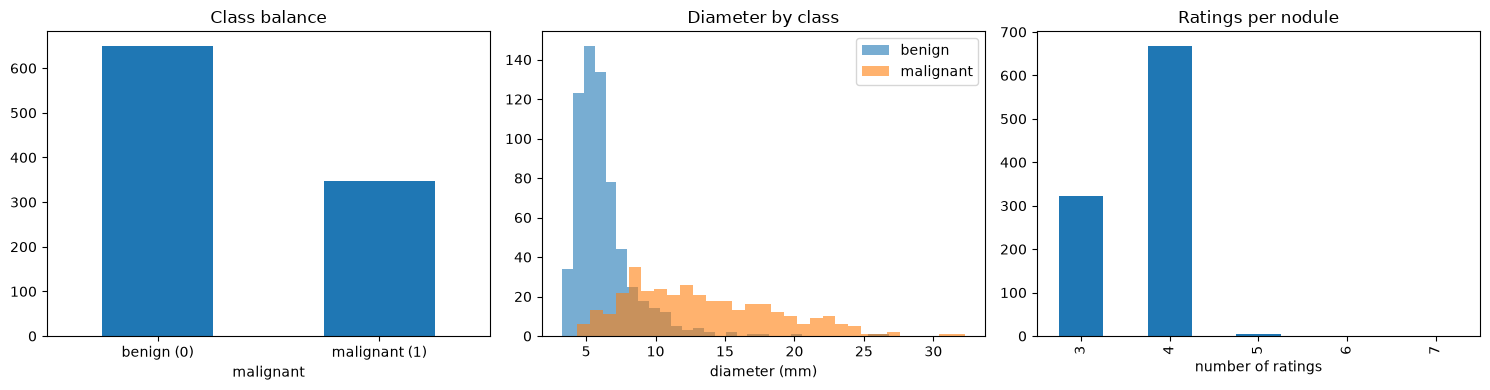

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# 1. How many benign vs malignant?
nod["malignant"].value_counts().sort_index().plot.bar(ax=ax[0])
ax[0].set_xticklabels(["benign (0)", "malignant (1)"], rotation=0)
ax[0].set_title("Class balance")

# 2. Are malignant nodules bigger?
for c, name in [(0, "benign"), (1, "malignant")]:
    ax[1].hist(nod.loc[nod["malignant"] == c, "diameter_mm"], bins=30, alpha=0.6, label=name)
ax[1].set_xlabel("diameter (mm)")
ax[1].legend()
ax[1].set_title("Diameter by class")

# 3. How many radiologists rated each nodule?
nod["n_annotations"].value_counts().sort_index().plot.bar(ax=ax[2])
ax[2].set_xlabel("number of ratings")
ax[2].set_title("Ratings per nodule")

plt.tight_layout()
plt.savefig("results/figures/eda/basic_overview.png", dpi=150)
plt.show()

In [20]:
VOI_IMG  = DATA / "VOIs" / "VOIs" / "image"
VOI_MASK = DATA / "VOIs" / "VOIs" / "nodule_mask"

voi_files  = sorted(VOI_IMG.glob("*.nii.gz"))
mask_files = sorted(VOI_MASK.glob("*.nii.gz"))
print(len(scan_files), len(voi_files), len(mask_files))

def describe_file(path, kind):
    img = nib.load(path)                          # reads the header only, not the pixels
    sx, sy, sz = img.header.get_zooms()[:3]       # voxel size in mm
    nx, ny, nz = img.shape                        # size in voxels
    return {
        "kind": kind,
        "file": path.name,
        "nx": nx, "ny": ny, "nz": nz,
        "sx": round(sx, 3), "sy": round(sy, 3), "sz": round(sz, 3),
        "orientation": "".join(nib.aff2axcodes(img.affine)),
    }

rows  = [describe_file(p, "full_ct")   for p in scan_files]
rows += [describe_file(p, "voi_image") for p in voi_files]
rows += [describe_file(p, "voi_mask")  for p in mask_files]

inv_all = pd.DataFrame(rows)
Path("data/processed").mkdir(parents=True, exist_ok=True)
inv_all.to_csv("data/processed/image_inventory.csv", index=False)
inv_all.head()

3 994 996


,kind,file,nx,ny,nz,sx,sy,sz,orientation
0,full_ct,LIDC-IDRI-0001.nii.gz,512,512,133,0.703,0.703,2.5,LPS
1,full_ct,LIDC-IDRI-0003.nii.gz,512,512,140,0.820,0.820,2.5,LPS
2,full_ct,LIDC-IDRI-0005.nii.gz,512,512,133,0.664,0.664,2.5,LPS
3,voi_image,LIDC-IDRI-0001_R_1.nii.gz,53,64,11,0.703,0.703,2.5,LPS
4,voi_image,LIDC-IDRI-0003_R_2.nii.gz,55,48,12,0.820,0.820,2.5,LPS


In [21]:
print("--- Orientation (how many files of each kind) ---")
print(inv_all.groupby("kind")["orientation"].value_counts(), "\n")

print("--- Spacing summary ---")
print(inv_all.groupby("kind")[["sx", "sy", "sz"]].describe().T)

print("\n--- Slice thickness values (sz) among VOI images ---")
print(inv_all[inv_all["kind"] == "voi_image"]["sz"].value_counts().sort_index())

print("\n--- In-plane pixel size (sx) among VOI images ---")
print(inv_all[inv_all["kind"] == "voi_image"]["sx"].describe())

--- Orientation (how many files of each kind) ---
kind       orientation
full_ct    LPS              3
voi_image  LPS            972
           RAS             22
voi_mask   LPS            974
           RAS             22
Name: count, dtype: int64 

--- Spacing summary ---
kind       full_ct   voi_image    voi_mask
sx count  3.000000  994.000000  996.000000
   mean   0.729000    0.698810    0.698525
   std    0.081185    0.084536    0.084689
   min    0.664000    0.461000    0.461000
   25%    0.683500    0.645000    0.645000
   50%    0.703000    0.703000    0.703000
   75%    0.761500    0.742000    0.742000
   max    0.820000    0.977000    0.977000
sy count  3.000000  994.000000  996.000000
   mean   0.729000    0.698810    0.698525
   std    0.081185    0.084536    0.084689
   min    0.664000    0.461000    0.461000
   25%    0.683500    0.645000    0.645000
   50%    0.703000    0.703000    0.703000
   75%    0.761500    0.742000    0.742000
   max    0.820000    0.977000    0.9

In [22]:
hu_rows = []
for p in voi_files:
    vol = np.asanyarray(nib.load(p).dataobj)       # now we load the actual pixels
    hu_rows.append({
        "file": p.name,
        "dtype": str(vol.dtype),
        "hu_min": float(vol.min()),
        "hu_max": float(vol.max()),
        "hu_mean": float(vol.mean()),
    })
hu = pd.DataFrame(hu_rows)

print(hu["dtype"].value_counts())
print(hu[["hu_min", "hu_max", "hu_mean"]].describe())

dtype
int16    994
Name: count, dtype: int64
            hu_min       hu_max     hu_mean
count   994.000000   994.000000  994.000000
mean   -988.073441   834.518109 -637.721466
std      48.738070   598.943733  162.980568
min   -1445.000000  -506.000000 -938.559041
25%   -1024.000000   299.750000 -777.402314
50%   -1005.000000   828.500000 -655.461072
75%    -960.000000  1201.500000 -516.886128
max    -789.000000  3071.000000  -82.269204


In [23]:
mask_rows = []
for p in voi_files:
    m_path = VOI_MASK / p.name                       # the mask should have the same file name
    if not m_path.exists():
        mask_rows.append({"file": p.name, "has_mask": False})
        continue
    a = nib.load(p)
    b = nib.load(m_path)
    md = np.asanyarray(b.dataobj)
    mask_rows.append({
        "file": p.name,
        "has_mask": True,
        "same_shape": a.shape == b.shape,
        "same_affine": bool(np.allclose(a.affine, b.affine)),
        "mask_values": tuple(np.unique(md).tolist()),
        "mask_voxels": int((md > 0).sum()),
    })
mk = pd.DataFrame(mask_rows)

print(mk["has_mask"].value_counts())
print(mk["same_shape"].value_counts())
print(mk["same_affine"].value_counts())
print(mk["mask_values"].value_counts())
print(mk["mask_voxels"].describe())

has_mask
True    994
Name: count, dtype: int64
same_shape
True    994
Name: count, dtype: int64
same_affine
True    994
Name: count, dtype: int64
mask_values
(0, 1)    994
Name: count, dtype: int64
count      994.000000
mean      1492.907445
std       2965.153785
min         36.000000
25%        188.250000
50%        400.500000
75%       1257.500000
max      33157.000000
Name: mask_voxels, dtype: float64


In [24]:
vi = inv_all[inv_all["kind"] == "voi_image"]
vm = inv_all[inv_all["kind"] == "voi_mask"]

# masks whose image is missing (names in the mask list but not in the image list)
print("masks without an image:", sorted(set(vm["file"]) - set(vi["file"])))

# slice thickness: the part that was cut off in your output
print(vi["sz"].value_counts().sort_index())

# are pixels square? (counts files where sx differs from sy)
print("non-square pixels:", (vi["sx"] != vi["sy"]).sum())

# names of the 22 RAS files
ras_files = vi.loc[vi["orientation"] == "RAS", "file"].tolist()
print(len(ras_files), ras_files[:5])

masks without an image: ['LIDC-IDRI-1002_R_1.nii.gz', 'LIDC-IDRI-1002_R_2.nii.gz']
sz
0.450      4
0.500      8
0.625    118
0.700     34
0.750     11
1.000    161
1.250    275
1.800     76
2.000     34
2.500    273
Name: count, dtype: int64
non-square pixels: 0
22 ['LIDC-IDRI-0262_R_1.nii.gz', 'LIDC-IDRI-0311_R_2.nii.gz', 'LIDC-IDRI-0313_R_1.nii.gz', 'LIDC-IDRI-0415_R_1.nii.gz', 'LIDC-IDRI-0415_R_3.nii.gz']


In [26]:
rows = []
for name in ras_files:
    r = nod[nod["voi_name"] == name].iloc[0]          # the table row for this file
    voi = nib.load(VOI_IMG / name)
    dx, dy, dz = offset_vox(voi, r.coordX, r.coordY, r.coordZ)
    rows.append({"file": name, "dx": dx, "dy": dy, "dz": dz})
print(pd.DataFrame(rows)[["dx", "dy", "dz"]].describe().loc[["mean", "std", "min", "max"]])

            dx        dy        dz
mean -0.045329 -0.826834 -0.114787
std   1.246163  1.606499  0.575284
min  -3.850062 -5.728989 -1.146544
max   2.872426  0.539313  1.415318


In [25]:
def load_canonical(path):
    img = nib.as_closest_canonical(nib.load(path))   # flips axes so every file ends up in RAS
    return img, np.asanyarray(img.dataobj)

orient = {"".join(nib.aff2axcodes(load_canonical(p)[0].affine)) for p in voi_files}
print(orient)       # expect {'RAS'}

{'RAS'}


In [27]:
# 1. Which of the two LIDC-IDRI-0332 nodules does the image file belong to?
voi = nib.load(VOI_IMG / "LIDC-IDRI-0332_R_1.nii.gz")
cand = nod[(nod["patient_id"] == "LIDC-IDRI-0332") & (nod["nodule_id"] == 1)]
dist = {r["part"]: np.linalg.norm(offset_vox(voi, r.coordX, r.coordY, r.coordZ))
        for _, r in cand.iterrows()}
owner = min(dist, key=dist.get)
print("distance from VOI center (voxels):", dist, "-> image belongs to part", owner)

# 2. The other 0332 nodule has no image: mark it
drop = (nod["patient_id"] == "LIDC-IDRI-0332") & (nod["nodule_id"] == 1) & (nod["part"] != owner)
nod.loc[drop, "has_voi"] = False

# 3. Keep only nodules with an image, and attach each image's properties
props = vi[["file", "nx", "ny", "nz", "sx", "sz", "orientation"]].rename(columns={"file": "voi_name"})
final = nod[nod["has_voi"]].merge(props, on="voi_name", how="left")

assert final["voi_name"].is_unique          # one row per image file
print(len(final), final["malignant"].value_counts().to_dict())
final.to_csv("data/processed/nodules.csv", index=False)

distance from VOI center (voxels): {0: np.float64(1.226625786126068), 1: np.float64(34.86287847862892)} -> image belongs to part 0
994 {0: 650, 1: 344}


In [28]:
final["thickness"] = pd.cut(final["sz"], [0, 1.0, 1.5, 3.0],
                            labels=["thin (<=1.0)", "1.25", "thick (>=1.8)"])
final["pixel_size"] = pd.qcut(final["sx"], 3, labels=["small", "medium", "large"])

print(final.groupby("thickness", observed=True)["malignant"].agg(["count", "mean"]).round(2))
print(final.groupby("pixel_size", observed=True)["malignant"].agg(["count", "mean"]).round(2))

               count  mean
thickness                 
thin (<=1.0)     336  0.29
1.25             275  0.33
thick (>=1.8)    383  0.40
            count  mean
pixel_size             
small         382  0.31
medium        286  0.34
large         326  0.39


In [32]:
from scipy.stats import chi2_contingency
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

# 1. Could the thickness gap be chance?
tab = pd.crosstab(final["thickness"], final["malignant"])
chi2, p, dof, expected = chi2_contingency(tab)
print(tab, "\np-value:", round(p, 4))

# 2. Do thick-slice scans simply contain bigger nodules?
print(final.groupby("thickness", observed=True)["diameter_mm"].describe().round(1))

# 3. How much can the scanner settings alone predict the label?
X = final[["sz", "sx"]].values
y = final["malignant"].values
pred = cross_val_predict(LogisticRegression(), X, y,
                         cv=GroupKFold(5), groups=final["patient_id"],
                         method="predict_proba")[:, 1]
print("AUC from scanner settings only:", round(roc_auc_score(y, pred), 3))

malignant        0    1
thickness              
thin (<=1.0)   238   98
1.25           184   91
thick (>=1.8)  228  155 
p-value: 0.0053
               count  mean  std  min  25%  50%   75%   max
thickness                                                 
thin (<=1.0)   336.0   7.7  4.1  3.3  4.9  6.2   9.3  23.9
1.25           275.0   8.0  4.8  3.3  5.0  6.0   9.2  27.4
thick (>=1.8)  383.0  10.0  5.4  3.8  5.9  8.1  12.7  32.3
AUC from scanner settings only: 0.566


In [33]:
# 1. Split nodules into three size groups, then look at malignant rate by thickness inside each
final["size_bin"] = pd.qcut(final["diameter_mm"], 3, labels=["small", "medium", "large"])
print(final.pivot_table(index="size_bin", columns="thickness", values="malignant",
                        aggfunc=["count", "mean"], observed=True).round(2))

# 2. Predictive power of different feature sets, using patient-level cross-validation
def cv_auc(cols):
    pred = cross_val_predict(LogisticRegression(max_iter=1000),
                             final[cols].values, final["malignant"].values,
                             cv=GroupKFold(5), groups=final["patient_id"],
                             method="predict_proba")[:, 1]
    return round(roc_auc_score(final["malignant"], pred), 3)

print("scanner only       :", cv_auc(["sz", "sx"]))
print("diameter only      :", cv_auc(["diameter_mm"]))
print("diameter + scanner :", cv_auc(["diameter_mm", "sz", "sx"]))

                 count                            mean                    
thickness thin (<=1.0) 1.25 thick (>=1.8) thin (<=1.0)  1.25 thick (>=1.8)
size_bin                                                                  
small              139  117            76         0.05  0.05          0.01
medium             107   84           140         0.21  0.24          0.15
large               90   74           167         0.76  0.88          0.80
scanner only       : 0.566
diameter only      : 0.918
diameter + scanner : 0.922


In [34]:
for b, g in final.groupby("size_bin", observed=True):
    auc = roc_auc_score(g["malignant"], g["diameter_mm"])
    print(f"{b:7s} n={len(g):4d}  diameter {g['diameter_mm'].min():.1f}-{g['diameter_mm'].max():.1f} mm"
          f"  malignant={g['malignant'].mean():.2f}  AUC of diameter inside group={auc:.3f}")

small   n= 332  diameter 3.3-5.7 mm  malignant=0.04  AUC of diameter inside group=0.729
medium  n= 331  diameter 5.7-8.7 mm  malignant=0.19  AUC of diameter inside group=0.779
large   n= 331  diameter 8.7-32.3 mm  malignant=0.80  AUC of diameter inside group=0.767


FileNotFoundError: [Errno 2] No such file or directory: 'results/figures/eda/diameter_vs_malignancy.png'

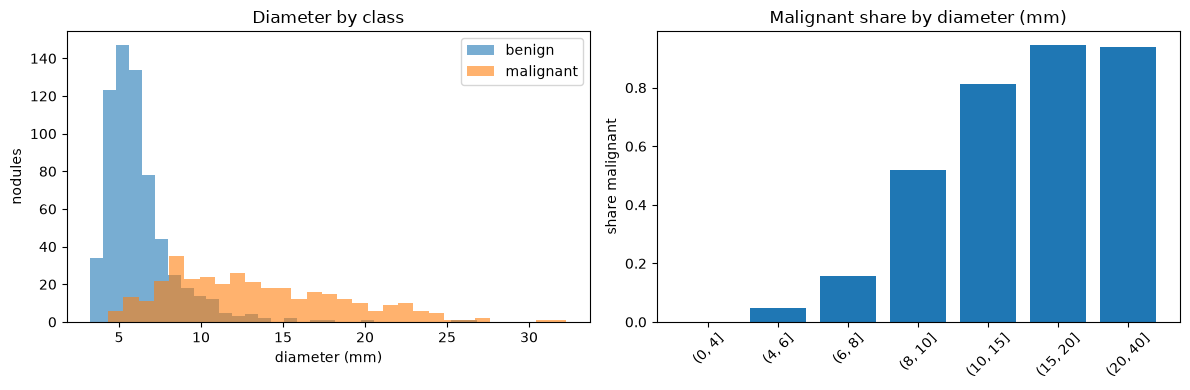

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for c, name in [(0, "benign"), (1, "malignant")]:
    ax[0].hist(final.loc[final["malignant"] == c, "diameter_mm"], bins=30, alpha=0.6, label=name)
ax[0].set_xlabel("diameter (mm)"); ax[0].set_ylabel("nodules")
ax[0].set_title("Diameter by class"); ax[0].legend()

edges = [0, 4, 6, 8, 10, 15, 20, 40]
rate = final.groupby(pd.cut(final["diameter_mm"], edges), observed=True)["malignant"].agg(["mean", "count"])
ax[1].bar(range(len(rate)), rate["mean"])
ax[1].set_xticks(range(len(rate)))
ax[1].set_xticklabels([str(i) for i in rate.index], rotation=45)
ax[1].set_ylabel("share malignant"); ax[1].set_title("Malignant share by diameter (mm)")

plt.tight_layout()
plt.savefig("results/figures/eda/diameter_vs_malignancy.png", dpi=150)
plt.show()
print(rate.round(2))

label_majority    0    1  All
label_pdf                    
0               650    0  650
1               116  228  344
All             766  228  994
label_mean    0    1  All
label_pdf                
0           575   75  650
1            15  329  344
All         590  404  994
n_high      0    1    2    3   4  5
n_raters                           
3         181   82   39   21   0  0
4         229  158  116  118  45  0
5           0    0    0    0   2  1
6           0    0    0    0   0  1
7           0    0    0    0   0  1


FileNotFoundError: [Errno 2] No such file or directory: 'results/figures/eda/rating_mean_hist.png'

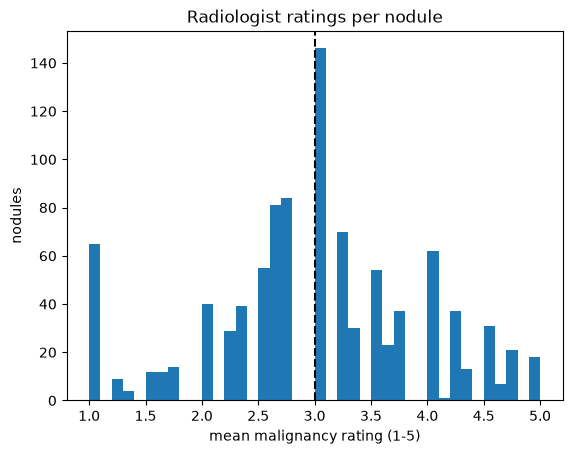

In [36]:
final["n_raters"] = final["ratings"].apply(len)
final["n_high"]   = final["ratings"].apply(lambda r: sum(x > 3 for x in r))   # ratings above 3
final["rating_mean"] = final["ratings"].apply(np.mean)

# three different ways to turn the ratings into a label
final["label_pdf"]      = (final["n_high"] >= 2).astype(int)                   # the rule from your PDF
final["label_majority"] = (final["n_high"] > final["n_raters"] / 2).astype(int)
final["label_mean"]     = (final["rating_mean"] > 3).astype(int)

assert (final["label_pdf"] == final["malignant"]).all()    # must reproduce your current label

print(pd.crosstab(final["label_pdf"], final["label_majority"], margins=True))
print(pd.crosstab(final["label_pdf"], final["label_mean"], margins=True))
print(final.groupby(["n_raters", "n_high"]).size().unstack(fill_value=0))

plt.hist(final["rating_mean"], bins=40)
plt.axvline(3, color="k", linestyle="--")
plt.xlabel("mean malignancy rating (1-5)"); plt.ylabel("nodules")
plt.title("Radiologist ratings per nodule")
plt.savefig("results/figures/eda/rating_mean_hist.png", dpi=150)
plt.show()

In [37]:
final["mm_z"] = final["nz"] * final["sz"]       # physical depth of each VOI
final["mm_x"] = final["nx"] * final["sx"]       # physical width of each VOI

print(final[["diameter_mm", "mm_x", "mm_z"]].corr(method="spearman").round(2))
for c in ["mm_x", "mm_z"]:
    print(c, "AUC alone:", round(roc_auc_score(final["malignant"], final[c]), 3))

             diameter_mm  mm_x  mm_z
diameter_mm         1.00  0.38  0.91
mm_x                0.38  1.00  0.34
mm_z                0.91  0.34  1.00
mm_x AUC alone: 0.62
mm_z AUC alone: 0.881
